# 02 — VGG16 Feature Extraction

Converts every Flickr8k image into one 4,096-number feature vector using a **frozen, ImageNet-pre-trained VGG16** (`fc2` layer), via `src/feature_extraction.py`.

* Input: RGB image resized to 224 × 224 × 3, preprocessed with `vgg16.preprocess_input`.
* Output: `data/features/features.npy` with shape (8091, 4096), plus `image_ids.json` (row order) and `metadata.json`.
* Each image is processed **once**, even though it has 5 captions.
* Extraction is resumable: re-running this notebook skips images that are already done.

The full run takes about 20 minutes on a laptop CPU. To run it on a Colab GPU instead, run `python -m src.feature_extraction` in Colab and copy `data/features/` back.

In [1]:
import os, sys, json, time, tempfile
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf, keras

from src.data_preprocessing import get_dataset_paths, load_captions
from src.feature_extraction import (
    build_encoder, load_image, preprocess_batch, extract_features,
    load_features, features_for_ids, DEFAULT_FEATURES_DIR,
)

print("TensorFlow", tf.__version__, "| Keras", keras.__version__)
print("GPUs visible to TensorFlow:", tf.config.list_physical_devices("GPU") or "none (running on CPU)")

TensorFlow 2.20.0 | Keras 3.15.1
GPUs visible to TensorFlow: none (running on CPU)


## 1. The encoder

We keep VGG16 up to `fc2` and drop the 1,000-class ImageNet `predictions` layer. Freezing means none of its ~134M weights change: they act as a fixed, general-purpose image feature extractor.

In [2]:
encoder = build_encoder()
print("Input shape :", encoder.input_shape)
print("Output shape:", encoder.output_shape)
print("Last layers :", [l.name for l in encoder.layers[-4:]])
print("Trainable weights:", len(encoder.trainable_weights),
      "| Frozen parameters:", f"{encoder.count_params():,}")

Input shape : (None, 224, 224, 3)
Output shape: (None, 4096)
Last layers : ['block5_pool', 'flatten', 'fc1', 'fc2']
Trainable weights: 0 | Frozen parameters: 134,260,544


## 2. Image loading and VGG16 preprocessing

`load_image` returns RGB values in 0–255. `preprocess_input` then swaps RGB → BGR and subtracts the ImageNet mean pixel — the same "caffe" preprocessing the original VGG16 weights were trained with. We do **not** rescale to [0, 1].

loaded      : (224, 224, 3) float32 range [1, 255] | top-left pixel RGB [82. 87. 97.]
preprocessed: (1, 224, 224, 3) range [-121.7, 148.1] | top-left pixel BGR - mean [ -6.94 -29.78 -41.68]


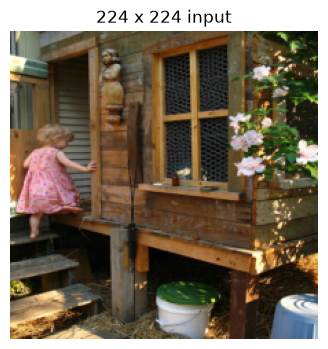

In [3]:
images_dir, captions_file = get_dataset_paths()
image_ids = sorted(load_captions(captions_file))
example = "1000268201_693b08cb0e.jpg"

img = load_image(images_dir / example)
pre = preprocess_batch(img[None])
print("loaded      :", img.shape, img.dtype, f"range [{img.min():.0f}, {img.max():.0f}]",
      "| top-left pixel RGB", img[0, 0])
print("preprocessed:", pre.shape, f"range [{pre.min():.1f}, {pre.max():.1f}]",
      "| top-left pixel BGR - mean", pre[0, 0, 0].round(2))

plt.figure(figsize=(4, 4)); plt.imshow(img.astype("uint8")); plt.title("224 x 224 input"); plt.axis("off"); plt.show()

## 3. CPU smoke test and benchmark (32 images, written to a temporary folder)

In [4]:
with tempfile.TemporaryDirectory() as tmp:
    t = time.perf_counter()
    extract_features(image_ids[:32], images_dir, tmp, batch_size=16, encoder=encoder, verbose=False)
    elapsed = time.perf_counter() - t
    f, row_of = load_features(tmp)
    print("smoke-test features:", f.shape, f.dtype, "| all finite:", np.isfinite(f).all())
    del f
rate = 32 / elapsed
print(f"{rate:.1f} images/s -> estimated full run: {len(image_ids) / rate / 60:.1f} min")

smoke-test features: (32, 4096) float32 | all finite: True
5.6 images/s -> estimated full run: 23.9 min


## 4. Full extraction (resumes; does nothing if already complete)

In [5]:
meta = extract_features(image_ids, images_dir, DEFAULT_FEATURES_DIR, batch_size=32, encoder=encoder)
print({k: meta[k] for k in ("layer", "feature_dim", "num_images", "num_extracted", "complete", "failed_images")})

8091 images, 8091 already extracted, 0 to do.
Done: 8091/8091 extracted, 0 failed, 0.0 s this run.
{'layer': 'fc2', 'feature_dim': 4096, 'num_images': 8091, 'num_extracted': 8091, 'complete': True, 'failed_images': {}}


## 5. Verify the saved features

In [6]:
features, row_of = load_features()
print("features:", features.shape, features.dtype, f"({features.nbytes / 1e6:.0f} MB)")
print("one row per image:", len(row_of) == features.shape[0] == len(set(image_ids)))
print("IDs match captions.txt:", set(row_of) == set(image_ids))
print("all values finite:", np.isfinite(features).all())
print(f"value range [{features.min():.2f}, {features.max():.2f}], "
      f"{100 * (features == 0).mean():.1f}% zeros (fc2 uses ReLU)")

# Alignment spot check: re-extract the example image and compare with its saved row.
fresh = encoder.predict_on_batch(preprocess_batch(load_image(images_dir / example)[None]))[0]
print("saved row matches fresh extraction:", np.allclose(features[row_of[example]], fresh, atol=1e-4))

features:

 (8091, 4096) float32 (133 MB)
one row per image: True
IDs match captions.txt: True


all values finite: True
value range [0.00, 25.64], 68.7% zeros (fc2 uses ReLU)


saved row matches fresh extraction: True


## 6. Match features to the Task #1 train / val / test split

The split comes from `data/processed/splits.json` (created in notebook 01), so image IDs and split membership are unchanged. Only training images will be used to fit the LSTM.

In [7]:
splits = json.loads((PROJECT_ROOT / "data" / "processed" / "splits.json").read_text())
for name, ids in splits.items():
    print(f"{name:5s}: {features_for_ids(features, row_of, ids).shape}")
print("every split image has a feature:", all(i in row_of for ids in splits.values() for i in ids))

train: (6472, 4096)
val  : (809, 4096)
test : (810, 4096)
every split image has a feature: True


## 7. How this connects to the LSTM (next task)

For each training pair from notebook 01 (`image_ids[k]`, `X[k]`, `y[k]`), the model receives:

* `features[row_of[image_ids[k]]]` → shape (4096,) → Dense(256) projection
* `X[k]` → shape (39,) word IDs → Embedding(256) → LSTM(256)

The two 256-d vectors are added, passed through Dense(256, ReLU) and a softmax over the 7,702-word vocabulary to predict `y[k]`. Looking features up by row (instead of copying them for all ~380k pairs) keeps memory at ~133 MB.